In [3]:
import matplotlib.pyplot as plt
import scienceplots
plt.style.use(["science", "no-latex"])
from Influence_Modelling import Network, XsvNetwork, Heuristics

In [4]:
net = XsvNetwork.XsvNetwork("airports")
N = net.get_nx()
Degree = Heuristics.deg_h(N, 100)
baseline = [N.degree(g) for g in N.nodes()]
degs = [N.degree(g) for g in Heuristics.deg_h(N, 100)]
cluster = [N.degree(g) for g in Heuristics.local_clustering_coefficient_h(N, 100)]
between = [N.degree(g) for g in Heuristics.betweenness_centrality_h(N, 100)]

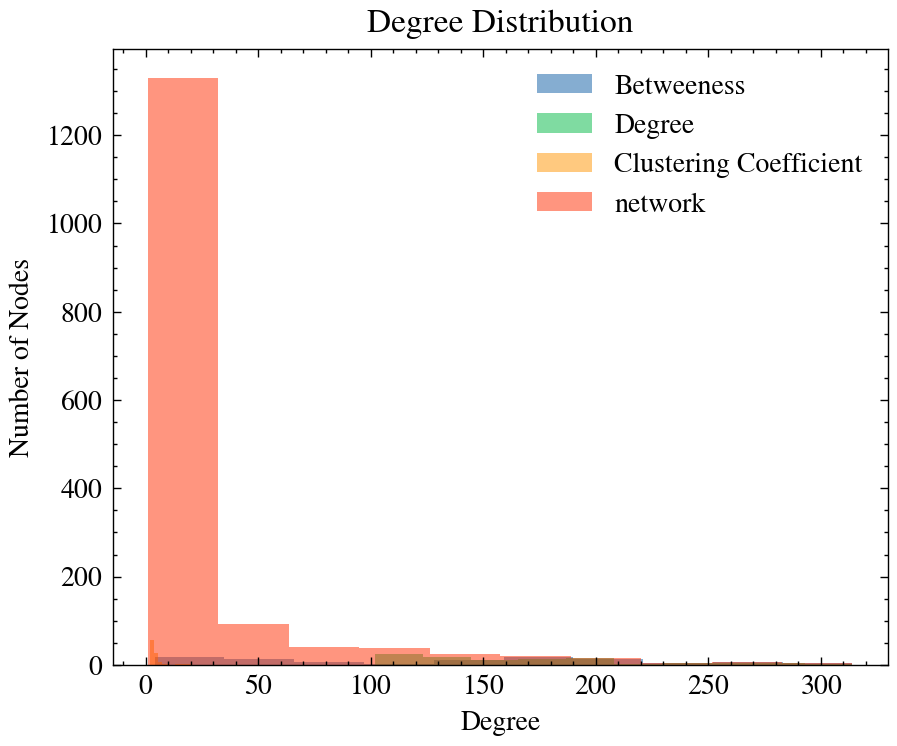

In [6]:
fig, ax = plt.subplots()
fig.set_size_inches(5,4)
fig.set_dpi(200)
ax.hist(between, label="Betweeness", alpha=0.5)
ax.hist(degs, label="Degree", alpha=0.5)
ax.hist(cluster, label="Clustering Coefficient", alpha=0.5)
ax.hist(baseline, label="network", alpha=0.5)
ax.set_xlabel("Degree")
ax.set_ylabel("Number of Nodes")
ax.set_title("Degree Distribution")
ax.legend()

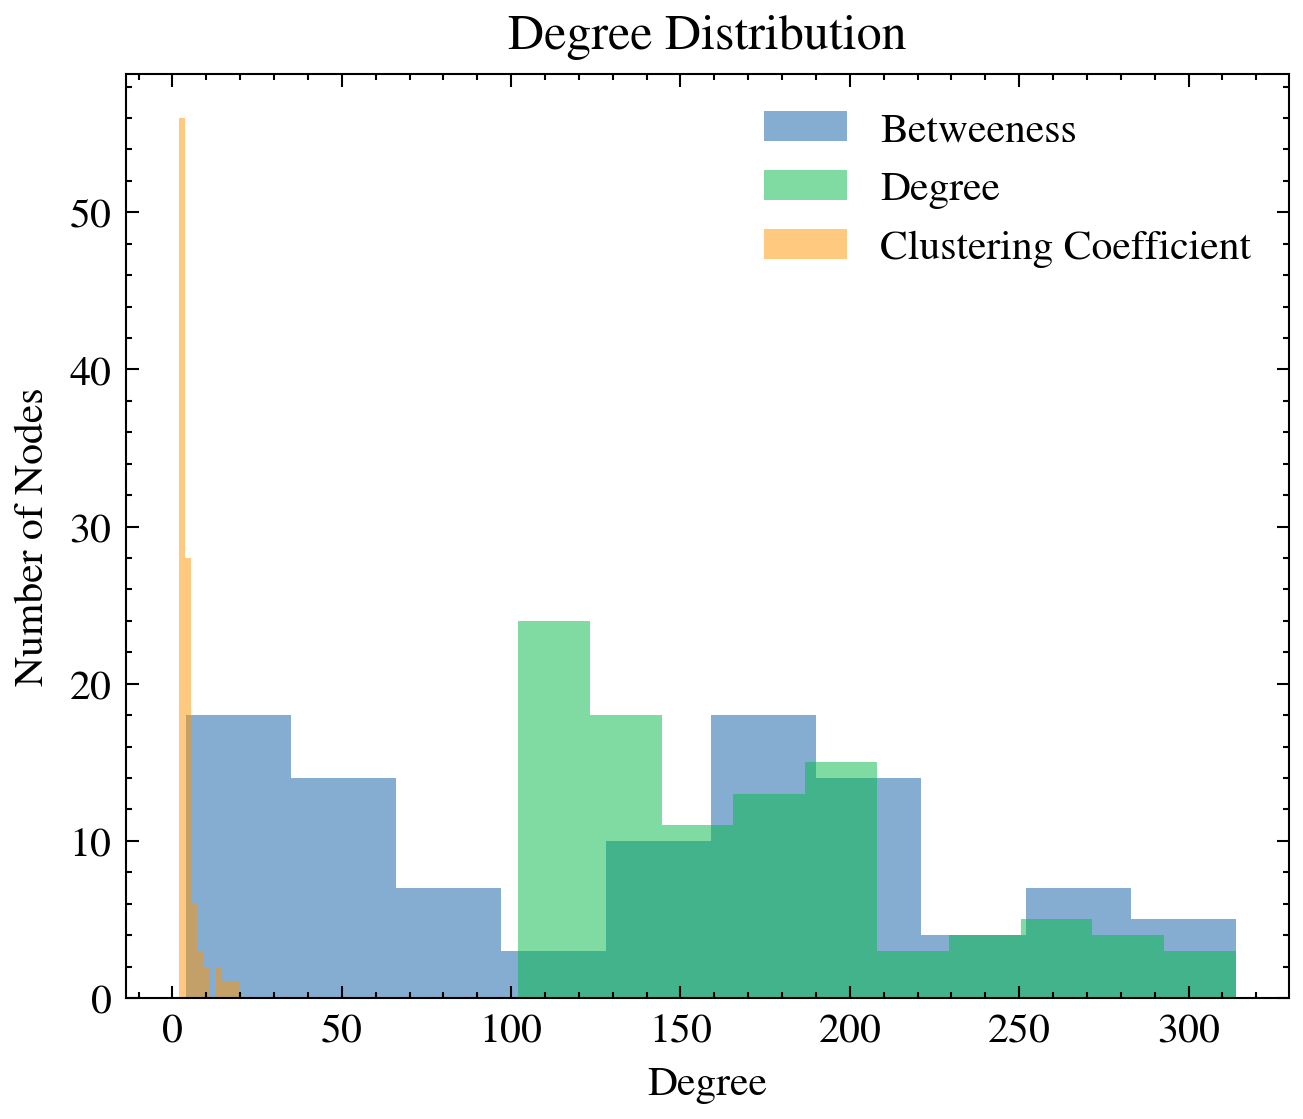

In [7]:
fig, ax = plt.subplots()
fig.set_size_inches(5,4)
fig.set_dpi(300)
ax.hist(between, label="Betweeness", alpha=0.5)
ax.hist(degs, label="Degree", alpha=0.5)
ax.hist(cluster, label="Clustering Coefficient", alpha=0.5)
#ax.hist(baseline, label="network", alpha=0.5)
ax.set_xlabel("Degree")
ax.set_ylabel("Number of Nodes")
ax.set_title("Degree Distribution")
ax.legend()

In [1]:
def plot_degree_histogram(G, axis, methods, labels, show_baseline, proportion=0.1):
  assert len(methods) == len(labels)
  assert type(show_baseline) == bool
  if show_baseline:
    methods.append(Heuristics.random_h)
    labels.append("Random (Baseline)")
  for i, method in enumerate(methods):
    axis.hist([G.degree(g) for g in method(G, round(proportion*len(G.nodes())))], label=labels[i], alpha=0.5)
  axis.set_xlabel("Degree")
  axis.set_ylabel("Number of Nodes")
  axis.set_title("Degree Distribution")
  axis.legend()

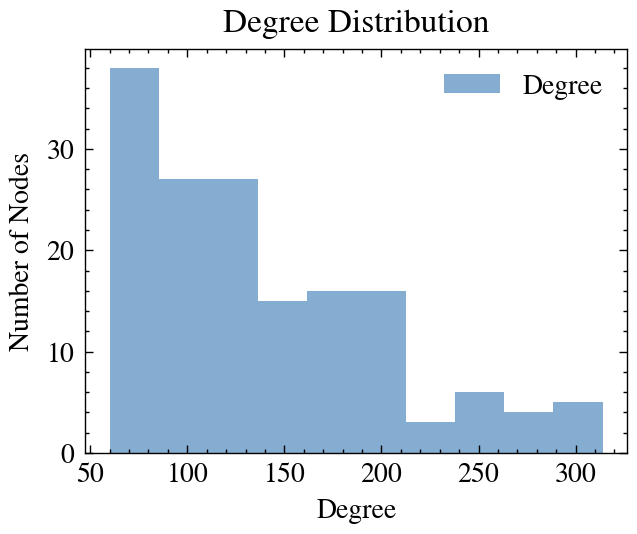

In [5]:
fig, ax = plt.subplots()
fig.set_dpi(200)
plot_degree_histogram(N, ax, [Heuristics.deg_h], ["Degree"], False)